# MROOT: data analysis

    I checked class balance, image quality, and related images before the final paired experiment.
    This notebook reads the saved audit and reviewed file lists. It contains no test images.
    The original images remain in Kaggle. Counts and figures below use the exported reports.


## Load the reviewed training and validation lists


In [1]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import Image as OutputImage, display

ROOT = next(
    (
        folder for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "notebooks/evidence").is_dir()
        and (folder / "class_mapping.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the complete repository checkout.")

EVIDENCE = ROOT / "notebooks/evidence"


def read_report(name):
    return json.loads((EVIDENCE / name).read_text(encoding="utf-8"))


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


In [2]:
train_manifest = EVIDENCE / "experiment_train.csv"
validation_manifest = EVIDENCE / "experiment_validation.csv"
split_summary = read_report("split_summary.json")

assert file_sha256(train_manifest) == split_summary["train_sha256"]
assert file_sha256(validation_manifest) == split_summary["validation_sha256"]

train = pd.read_csv(train_manifest)
validation = pd.read_csv(validation_manifest)
mapping = json.loads((ROOT / "class_mapping.json").read_text())
classes = sorted(mapping, key=mapping.get)

assert len(train) == 6790 and len(validation) == 388
assert set(train.label) == set(validation.label) == set(range(39))
assert not set(train.path) & set(validation.path)
assert not set(train.duplicate_group) & set(validation.duplicate_group)
assert all(mapping[row.disease] == row.label for row in train.itertuples())
assert all(mapping[row.disease] == row.label for row in validation.itertuples())

split_sizes = pd.DataFrame({
    "Split": ["Training", "Validation"],
    "Images": [len(train), len(validation)],
    "Disease classes": [train.disease.nunique(), validation.disease.nunique()],
})
display(split_sizes)


,Split,Images,Disease classes
0,Training,6790,39
1,Validation,388,39


## Class distribution

    Some diseases have many more examples than others. This motivated the sampling and loss comparisons.
    The final two runs both used class-balanced replacement sampling.


,Training,Validation
disease,,
powdery_mildew,755,10
rust,616,10
downy_mildew,602,10
canker,299,10
early_blight,250,10
septoria_leaf_spot,77,9
blossom_end_rot,76,10
brown_spot,76,10
bacterial_leaf_streak_(black_chaff),73,10


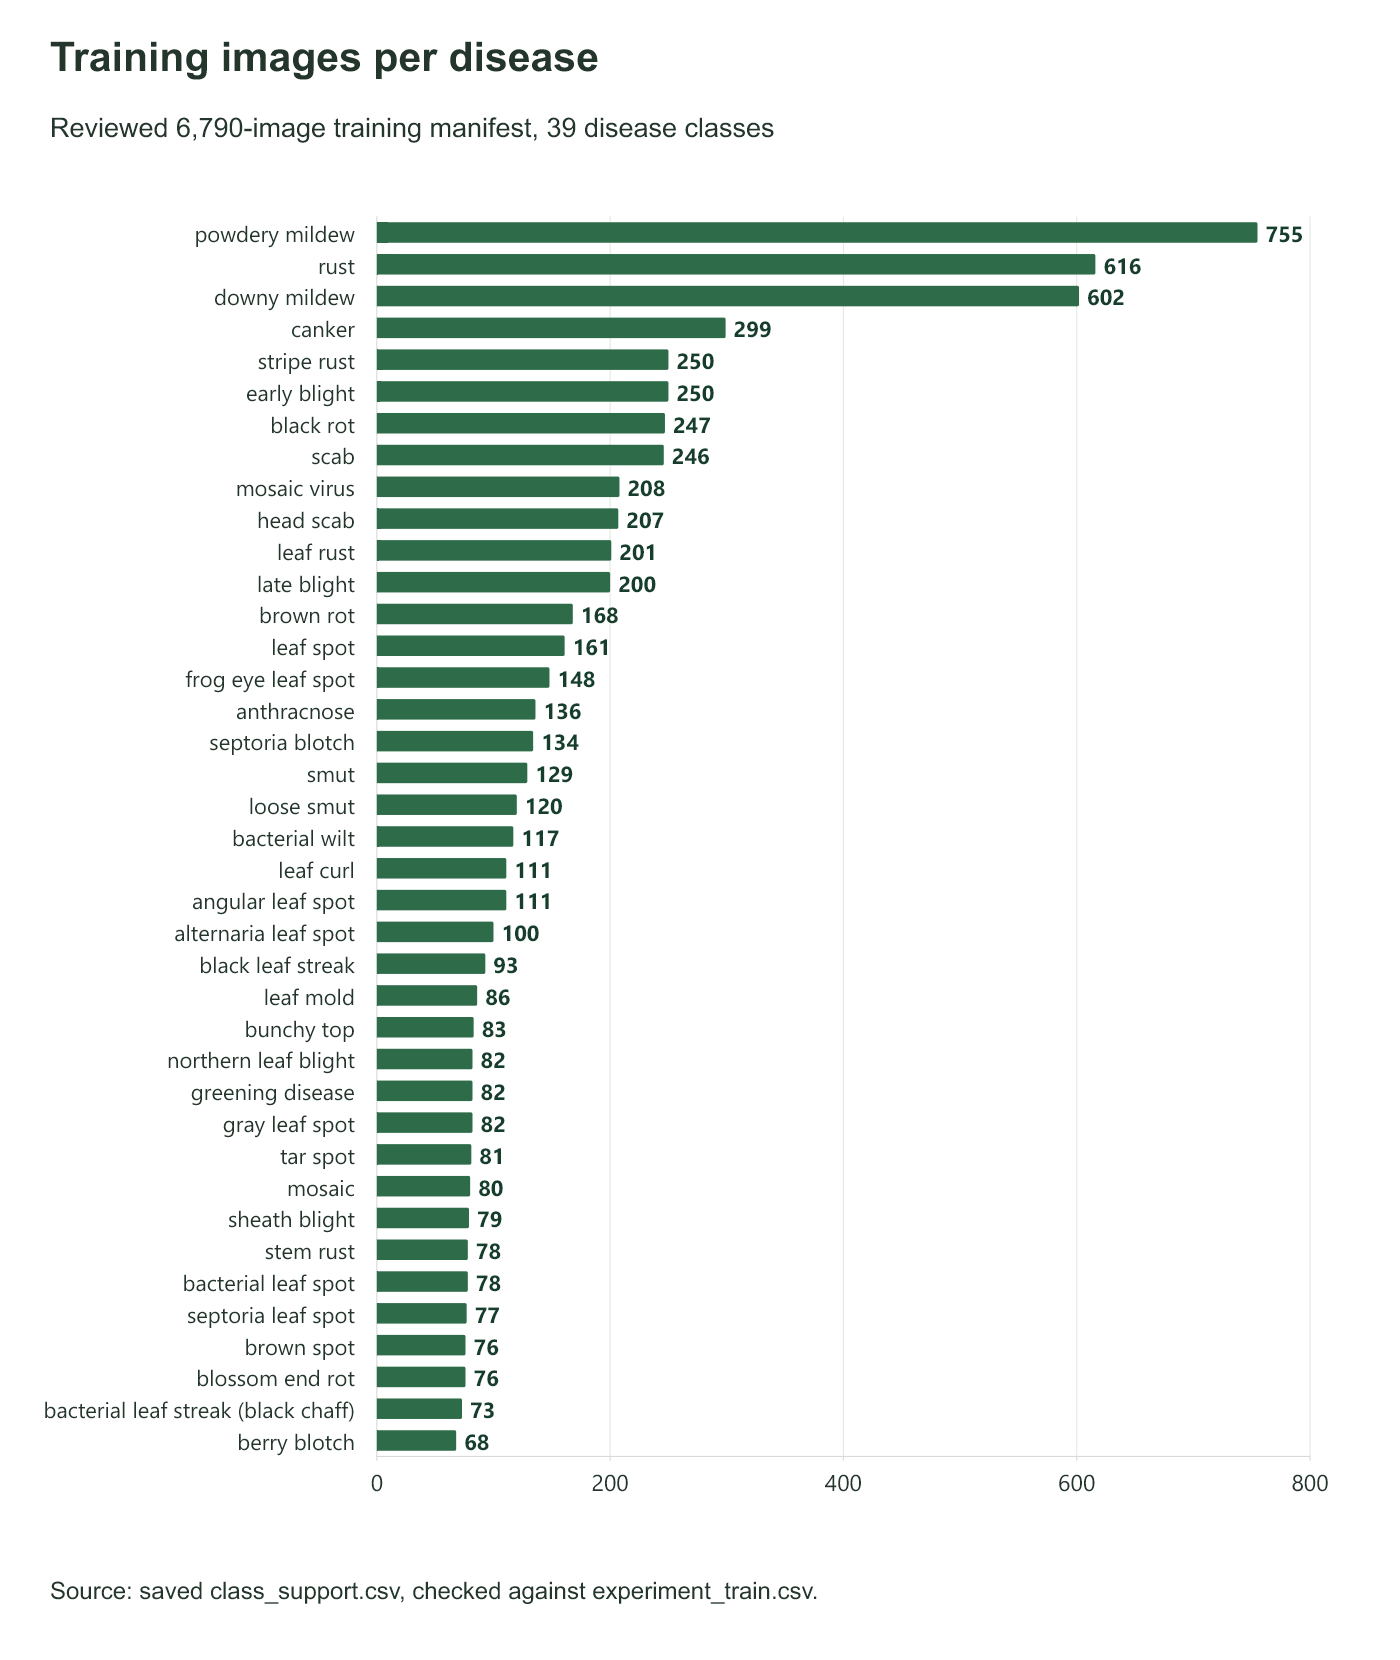

In [3]:
class_counts = (
    train.groupby("disease").size().rename("Training")
    .to_frame().join(validation.groupby("disease").size().rename("Validation"))
    .sort_values("Training", ascending=False)
)
saved_counts = pd.read_csv(EVIDENCE / "class_support.csv").set_index("disease")
assert class_counts["Training"].equals(saved_counts["train"].reindex(class_counts.index))
display(pd.concat([class_counts.head(5), class_counts.tail(5)]))
display(OutputImage(filename=str(ROOT / "notebooks/images/class_distribution.png")))


## File quality and image dimensions

    The saved audit checked 7,178 training/validation files. All were readable and had labels.
    The chart and table are views of that saved audit, not a new scan of image files.


,images,min_width,median_width,max_width,min_height,median_height,max_height
split,,,,,,,
train,6790,65,665.5,8256,59,534.0,5504
validation,388,90,693.0,4608,98,523.5,3456


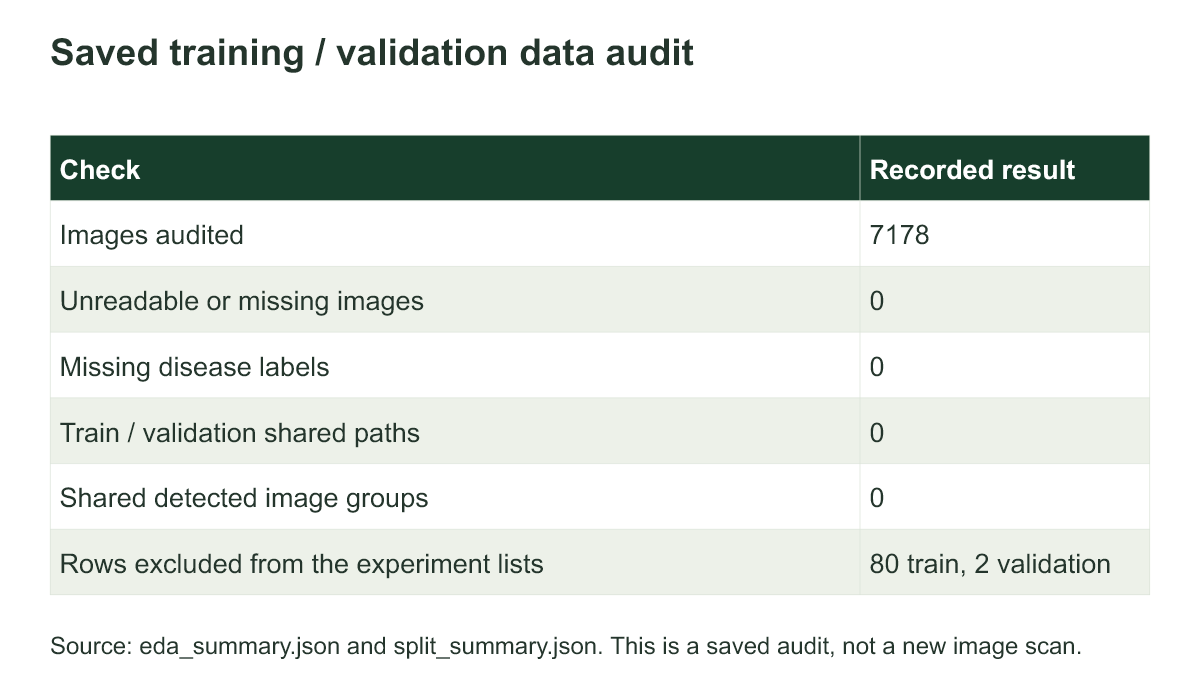

In [4]:
audit = read_report("eda_summary.json")
metadata = pd.read_csv(EVIDENCE / "image_metadata.csv")
assert len(metadata) == audit["images_checked"] == len(train) + len(validation)
assert metadata["error"].isna().all()

dimensions = metadata.groupby("split").agg(
    images=("width", "size"),
    min_width=("width", "min"),
    median_width=("width", "median"),
    max_width=("width", "max"),
    min_height=("height", "min"),
    median_height=("height", "median"),
    max_height=("height", "max"),
)
display(dimensions)
display(OutputImage(filename=str(ROOT / "notebooks/images/data_audit.png")))


The original scan opened each image and recorded its dimensions. This optional cell shows the same
    kind of inspection. It is off by default because the image files are not stored in GitHub.


In [5]:
CHECK_ORIGINAL_IMAGES = False


def inspect_image(row):
    try:
        with Image.open(row.path) as image:
            width, height = image.size
            image.verify()
        return {"path": row.path, "width": width, "height": height, "error": None}
    except Exception as error:
        return {"path": row.path, "error": str(error)}


if CHECK_ORIGINAL_IMAGES:
    # Այստեղ ստուգում ենք միայն train և validation նկարները։
    records = [inspect_image(row) for row in pd.concat([train, validation]).itertuples()]
    display(pd.DataFrame(records))
else:
    print("Showing the saved image audit. Original image files were not opened.")


Showing the saved image audit. Original image files were not opened.


## Related-image review

    The review excluded 80 training rows and two validation rows from the experiment lists,
    including a conflicting-label group. Original source files were preserved.
    Disjoint detected groups reduce leakage risk, but do not prove that every possible copy was found.


In [6]:
checks = pd.DataFrame({
    "Check": [
        "Shared file paths", "Shared detected image groups",
        "Training rows excluded", "Validation rows excluded",
        "Conflicting label groups",
    ],
    "Count": [
        len(set(train.path) & set(validation.path)),
        len(set(train.duplicate_group) & set(validation.duplicate_group)),
        split_summary["quarantined_train_rows"],
        split_summary["quarantined_validation_rows"],
        split_summary["conflicting_train_val_label_groups"],
    ],
})
display(checks)
print("Historical-copy-free validation subset:", int(validation.historical_copy_free.sum()))


,Check,Count
0,Shared file paths,0
1,Shared detected image groups,0
2,Training rows excluded,80
3,Validation rows excluded,2
4,Conflicting label groups,1


Historical-copy-free validation subset: 368


## Findings that guided the experiments

    I tested sampling and weighted loss because class counts were uneven. I used image augmentation
    to add variation and checked related-image groups to make comparisons more reliable.
    The reviewed lists contain 6,790 training and 388 validation images. Comparisons with older models
    use the 368-image historical-copy-free subset.

    Sources: `evidence/eda_summary.json`, `class_support.csv`, `split_summary.json`, and the two reviewed
    manifests. `evidence/provenance.json` records the source files and checksums.
